### Build A Basic Chatbot with LangGraph(GRAPH API)

In [3]:
from typing import Annotated
from typing_extensions import TypedDict
from langgraph.graph import StateGraph,START,END
from langgraph.graph.message import add_messages


In [4]:
class State(TypedDict):
    #Message have the type "list".The 'add_messages' function
    #in the annotation defines how this state key should be updated
    #(in this case,it appends messages to the list,rather than overwriting them)
    messages:Annotated[list,add_messages]
    


In [5]:
import os
from dotenv import load_dotenv
load_dotenv()

True

In [6]:
#there are two way to initialise the llm 
from langchain_groq import ChatGroq
from langchain.chat_models import init_chat_model

llm=ChatGroq(
    model="llama-3.1-8b-instant",
    api_key=os.getenv("GROQ_API_KEY"),
    temperature=0
)

In [7]:
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.6.9', 'langchain': '1.4.4'}}, profile={'name': 'Llama 3.1 8B Instant', 'release_date': '2024-07-23', 'last_updated': '2024-07-23', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 131072, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': False, 'tool_calling': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x0000015247CE1310>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x0000015247611370>, model_name='llama-3.1-8b-instant', temperature=1e-08, model_kwargs={}, groq_api_key=SecretStr('**********'))

In [8]:
llm=init_chat_model("groq:openai/gpt-oss-20b")
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.6.9', 'langchain': '1.4.4'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x0000015247E3E120>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x0000015247E3E840>, model_name='openai/gpt-oss-20b', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [9]:
## Node Functionality
def chatbot(state:State):
    return {"messages":[llm.invoke(state["messages"])]}

In [10]:
graph_builder=StateGraph(State)

##Adding node
graph_builder.add_node("llmchatbot",chatbot)
##Adding Edges
graph_builder.add_edge(START,"llmchatbot")
graph_builder.add_edge("llmchatbot",END)

##compile the graph
graph=graph_builder.compile()

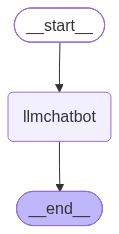

In [11]:
##visualize the graph
from IPython.display import Image,display

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    pass

In [12]:
response=graph.invoke({"messages":"Hi"})

In [13]:
response["messages"][-1].content

'Hello! 👋 How can I help you today?'

In [14]:
for event in graph.stream({"messages":"Hii How are you?"}):
    ## print(event)
    for value in event.values():
        print(value["messages"][-1].content)

Hi there! 👋 I’m doing great—just ready to help you out. What’s on your mind today?


### ChatBot With Tool

In [15]:
import os
from dotenv import load_dotenv

load_dotenv(override=True)

os.getenv("TAVILY_API_KEY")

'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'

In [16]:
from langchain_tavily import TavilySearch

tool=TavilySearch(max_result=2)
tool.invoke("What is langgraph")

{'query': 'What is langgraph',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://www.geeksforgeeks.org/machine-learning/what-is-langgraph',
   'title': 'What is LangGraph - GeeksforGeeks',
   'content': 'LangGraph is an open-source framework from LangChain designed to build and manage AI agent workflows using graph-based structures. It allows developers to define workflows as nodes and edges, making complex agent interactions more structured, scalable and easier to control. [...] langgraph: Framework for building graph-based AI workflows.\n langchain: Popular toolkit for LLM-powered AI applications.\n google-generativeai: Google’s API for Generative AI (Gemini models).\n\n Python  ````\n! pip install langgraph langchain google - generativeai\n```` \n\n### Step 2: Setup Gemini API [...] ## Building a Simple Chatbot with LangGraph\n\nLangGraph makes it easy to build structured, stateful applications like chatbots. In this example we’ll learn how 

In [38]:
### custome function
def multiply(a:int,b:int)->int:
    """Multiply a and b
    
    Args:
        a (int):first int
        b (int):second int
        
    Returns:
        int:output int
    """
    return a*b

In [40]:
tools=[tool,multiply]

In [41]:
llm_with_tool=llm.bind_tools(tools)

In [42]:
llm_with_tool

_ChatModelBinding(bound=ChatGroq(metadata={'lc_versions': {'langchain-core': '1.6.9', 'langchain': '1.4.4'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x0000015247E3E120>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x0000015247E3E840>, model_name='openai/gpt-oss-20b', model_kwargs={}, groq_api_key=SecretStr('**********')), kwargs={'tools': [{'type': 'function', 'function': {'name': 'tavily_search', 'description': 'A search engine optimized for comprehensive, accurate, and 

In [43]:
### Sategraph
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

## Node definition
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tool.invoke(state["messages"])]}

##Graph
builder=StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

## Add Edges
builder.add_edge(START,"tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    #if the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    #if the latest meassage (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition
)
builder.add_edge("tools",END)

## compile the graph
graph=builder.compile()

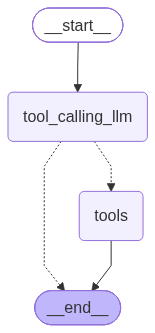

In [44]:
from IPython.display import Image,display
display(Image(graph.get_graph().draw_mermaid_png()))

In [45]:
response=graph.invoke({"messages":"what is the recent ai news"})

In [46]:
response['messages'][-1].content

'{"query": "latest AI news", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://simplywall.st/stocks/us/pharmaceuticals-biotech/nyse-qgen/qiagen/news/qiagen-qgen-looks-fairly-valued-as-new-ai-tools-aim-to-speed", "title": "Qiagen (QGEN) Looks Fairly Valued As New AI Tools Aim To Speed Drug Discovery - Simply Wall St News", "content": "## Most Popular Narrative: 5% Undervalued\\n\\nQiagen’s most followed valuation narrative puts fair value at $47.80 per share, slightly above the last close of $45.44. This frames the recent AI news against expectations for steady but measured progress.\\n\\n> Ongoing growth of digital PCR and bioinformatics, with QIAcuity consumables demand and a larger assay menu and with Qiagen Digital Insights supported by long curated biomedical data and new AI collaborations, provides higher margin product lines that can contribute to earnings growth as utilization builds on the existing instrument and software base.\\n\\nSee why

In [47]:
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

what is the recent ai news
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_ba6bbfcc-7ef9-4920-92ad-4a7c0ecc7fdc)
 Call ID: fc_ba6bbfcc-7ef9-4920-92ad-4a7c0ecc7fdc
  Args:
    query: latest AI news
    search_depth: advanced
    time_range: day
    topic: news
================================= Tool Message =================================
Name: tavily_search

{"query": "latest AI news", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://simplywall.st/stocks/us/pharmaceuticals-biotech/nyse-qgen/qiagen/news/qiagen-qgen-looks-fairly-valued-as-new-ai-tools-aim-to-speed", "title": "Qiagen (QGEN) Looks Fairly Valued As New AI Tools Aim To Speed Drug Discovery - Simply Wall St News", "content": "## Most Popular Narrative: 5% Undervalued\n\nQiagen’s most followed valuation narrative puts fair value at $47.80 per 

In [50]:
response=graph.invoke({"messages":"What is 2 multiply by 3"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

What is 2 multiply by 3
================================== Ai Message ==================================

2 multiplied by 3 is **6**.


In [53]:
response=graph.invoke({"messages":"Give me the recent ai news and then multiply 5  by 10 "})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

Give me the recent ai news and then multiply 5  by 10 
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_0cef9b4e-3319-45b0-804e-11232c946dc9)
 Call ID: fc_0cef9b4e-3319-45b0-804e-11232c946dc9
  Args:
    query: recent AI news 2026 October
    search_depth: basic
    topic: news
================================= Tool Message =================================
Name: tavily_search

{"query": "recent AI news 2026 October", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://cryptobriefing.com/anthropic-and-openai-reportedly-close-to-solving-recursive-self-improvement-in/", "title": "Anthropic and OpenAI reportedly close to solving recursive self-improvement in AI models - Crypto Briefing", "score": 0.8638634, "published_date": "Wed, 23 Sep 2026 00:38:17 GMT", "content": "Best AI model by october 2026 ↗. # Anthro

### ReAct Agent Architecture

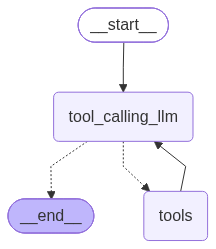

In [55]:
### Sategraph
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

## Node definition
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tool.invoke(state["messages"])]}

##Graph
builder=StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

## Add Edges
builder.add_edge(START,"tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    #if the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    #if the latest meassage (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition
)
builder.add_edge("tools","tool_calling_llm")

## compile the graph
graph=builder.compile()
from IPython.display import Image,display
display(Image(graph.get_graph().draw_mermaid_png()))

In [56]:
response=graph.invoke({"messages":"Give me the recent ai news and then multiply 5  by 10 "})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

Give me the recent ai news and then multiply 5  by 10 
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_29719c68-fdd1-46d7-b686-367d87605b79)
 Call ID: fc_29719c68-fdd1-46d7-b686-367d87605b79
  Args:
    query: recent AI news 2026
    search_depth: basic
    time_range: day
================================= Tool Message =================================
Name: tavily_search

{"query": "recent AI news 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://aiweekly.co/ai-news-today", "title": "AI News Today, October 15: Top Stories | AI Weekly", "content": "Microsoft, Japanese authorities and Health-ISAC dismantled Storm-2990, an interconnected network of Chinese-language phishing kits (YAM Store, CoGUI, Iron Man) that sent 1B+ phishing emails and SMS messages to 75,000+ organizations since January 2026, h

In [57]:
response=graph.invoke({"messages":"Hello my name is Saurabh"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

Hello my name is Saurabh
================================== Ai Message ==================================

Hi Saurabh! 👋 How can I help you today?


In [58]:
response=graph.invoke({"messages":"What is my name"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

What is my name
================================== Ai Message ==================================

I don’t have any information about your name. If you’d like me to address you by a particular name, just let me know!


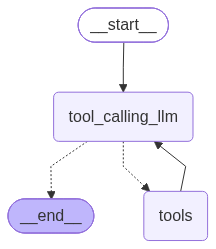

In [59]:
### Sategraph
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition
from langgraph.checkpoint.memory import MemorySaver

memory=MemorySaver()
## Node definition
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tool.invoke(state["messages"])]}

##Graph
builder=StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

## Add Edges
builder.add_edge(START,"tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    #if the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    #if the latest meassage (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition
)
builder.add_edge("tools","tool_calling_llm")

## compile the graph
graph=builder.compile(checkpointer=memory)
from IPython.display import Image,display
display(Image(graph.get_graph().draw_mermaid_png()))

In [62]:
config={"configurable":{"thread_id":"1"}}
response=graph.invoke({"messages":"Hi my name is Saurabh"},config=config)
response

{'messages': [HumanMessage(content='Hi my name is Saurabh', additional_kwargs={}, response_metadata={}, id='c728dbac-2ad2-487f-a1d8-f97adc3d6480'),
  AIMessage(content='Hello Saurabh! How can I help you today?', additional_kwargs={'reasoning_content': 'We just greet.'}, response_metadata={'token_usage': {'completion_tokens': 26, 'prompt_tokens': 349, 'total_tokens': 375, 'completion_time': 0.026349764, 'completion_tokens_details': {'reasoning_tokens': 5}, 'prompt_time': 0.01830096, 'prompt_tokens_details': None, 'queue_time': 0.381219479, 'total_time': 0.044650724}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_e11c8bbf69', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a13f1d-74c2-7262-a5a6-3dcc4f707bb4-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 349, 'output_tokens': 26, 'total_tokens': 375, 'output_token_details': {'reasoning': 5}})]}

In [64]:
response['messages'][-1].content

'Hello Saurabh! How can I help you today?'

In [65]:
response=graph.invoke({"messages":"Hey What is my name"},config=config)
response

{'messages': [HumanMessage(content='Hi my name is Saurabh', additional_kwargs={}, response_metadata={}, id='c728dbac-2ad2-487f-a1d8-f97adc3d6480'),
  AIMessage(content='Hello Saurabh! How can I help you today?', additional_kwargs={'reasoning_content': 'We just greet.'}, response_metadata={'token_usage': {'completion_tokens': 26, 'prompt_tokens': 349, 'total_tokens': 375, 'completion_time': 0.026349764, 'completion_tokens_details': {'reasoning_tokens': 5}, 'prompt_time': 0.01830096, 'prompt_tokens_details': None, 'queue_time': 0.381219479, 'total_time': 0.044650724}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_e11c8bbf69', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a13f1d-74c2-7262-a5a6-3dcc4f707bb4-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 349, 'output_tokens': 26, 'total_tokens': 375, 'output_token_details': {'reasoning': 5}}),
  HumanMessage(content='Hey What is my 

In [66]:
response['messages'][-1].content

'Your name is Saurabh.'

In [69]:
response=graph.invoke({"messages":"Hey do you remember my name"},config=config)
print(response['messages'][-1].content)

Yes—I remember you said your name is Saurabh.


### Streaming


In [70]:
from langgraph.checkpoint.memory import MemorySaver
memory=MemorySaver()

In [71]:
def superbot(state:State):
    return {"messages":[llm.invoke(state['messages'])]}

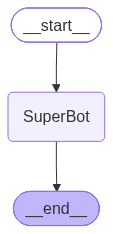

In [73]:
graph=StateGraph(State)

##node
graph.add_node("SuperBot",superbot)
##Edges

graph.add_edge(START,"SuperBot")
graph.add_edge("SuperBot",END)

graph_builder=graph.compile(checkpointer=memory)

##Display
from IPython.display import Image,display
display(Image(graph_builder.get_graph().draw_mermaid_png()))

In [75]:
## Invocation
config={"configurable":{"thread_id":"1"}}

graph_builder.invoke({'messages':"Hii,My name is Saurabh and I like football"},config=config)

{'messages': [HumanMessage(content='Hii,My name is Saurabh and I like football', additional_kwargs={}, response_metadata={}, id='e5935aa5-52cb-4514-84be-1775315eb66b'),
  AIMessage(content='Hi Saurabh! 👋\n\nIt’s great to hear you’re into football. Whether you’re a fan of the Premier League, La Liga, the World Cup, or just love watching local matches, I’m here to chat about it—or anything else you’re curious about. How can I help you today?', additional_kwargs={'reasoning_content': 'We have a user greeting: "Hii,My name is Saurabh and I like football". We should respond politely, ask for further instructions or ask how we can help. Also maybe ask about football. The user hasn\'t asked a question yet. We can respond with friendly greeting, mention we can help with various topics. Also ask about football preferences. Provide an open-ended response.'}, response_metadata={'token_usage': {'completion_tokens': 152, 'prompt_tokens': 84, 'total_tokens': 236, 'completion_time': 0.208517267, 'com

### Streaming
Methods: .stream() and astream()

>These methods are sync and async methods for streaming back results.

Additional parameters in streaming modes for graph state

-valuse: This streams the full state of the graph after each node in called.

-updates:This streams updates to the state of the graph after each node is called.

In [ ]:
#create a thread
config={"configurable":{"thread_id":"3"}}

for chunk in graph_builder.stream({'messages':"Hi,My name is saurabh and i like football"},config,stream_mode="updates"):
    print(chunk)

{'SuperBot': {'messages': [AIMessage(content='Hey Saurabh! 👋 Great to meet you. It’s awesome that you’re into football. What’s your favorite team or player? Are you a fan of any particular league or position on the field? Let me know—I’d love to hear more!', additional_kwargs={'reasoning_content': 'We need to respond to user greeting. The user says: "Hi,My name is saurabh and i like football". We should greet them, confirm name, mention football interest, ask follow-up. It\'s a friendly conversation. We can ask about favorite team, position, etc. Use friendly tone.'}, response_metadata={'token_usage': {'completion_tokens': 124, 'prompt_tokens': 82, 'total_tokens': 206, 'completion_time': 0.147648202, 'completion_tokens_details': {'reasoning_tokens': 62}, 'prompt_time': 0.004535008, 'prompt_tokens_details': None, 'queue_time': 0.333464568, 'total_time': 0.15218321}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_976a85d17a', 'service_tier': 'on_demand', 'finish_reason': '

In [77]:
for chunk in graph_builder.stream({'messages':"Hi,My name is saurabh and i like football"},config,stream_mode="values"):
    print(chunk)

{'messages': [HumanMessage(content='Hi,My name is saurabh and i like football', additional_kwargs={}, response_metadata={}, id='45ffbb84-3db6-4b01-b04d-c98a2112043b'), AIMessage(content='Hey Saurabh! 👋 Great to meet you. It’s awesome that you’re into football. What’s your favorite team or player? Are you a fan of any particular league or position on the field? Let me know—I’d love to hear more!', additional_kwargs={'reasoning_content': 'We need to respond to user greeting. The user says: "Hi,My name is saurabh and i like football". We should greet them, confirm name, mention football interest, ask follow-up. It\'s a friendly conversation. We can ask about favorite team, position, etc. Use friendly tone.'}, response_metadata={'token_usage': {'completion_tokens': 124, 'prompt_tokens': 82, 'total_tokens': 206, 'completion_time': 0.147648202, 'completion_tokens_details': {'reasoning_tokens': 62}, 'prompt_time': 0.004535008, 'prompt_tokens_details': None, 'queue_time': 0.333464568, 'total_t

In [78]:
#create a thread
config={"configurable":{"thread_id":"4"}}

for chunk in graph_builder.stream({'messages':"Hi,My name is saurabh and i like football"},config,stream_mode="updates"):
    print(chunk)

{'SuperBot': {'messages': [AIMessage(content='Hello Saurabh! 👋 Great to meet you. It’s awesome that you’re into football. Which team do you follow most? Or maybe you enjoy playing it yourself? Let me know what you’re into, and we can chat more about the sport, recent matches, or anything else that catches your interest!', additional_kwargs={'reasoning_content': 'We need to respond as ChatGPT. The user says: "Hi,My name is saurabh and i like football". Likely a greeting. We should respond friendly. Maybe ask about football interest. Also note guidelines: no disallowed content. It\'s fine. No policy issues. We can comply.'}, response_metadata={'token_usage': {'completion_tokens': 135, 'prompt_tokens': 82, 'total_tokens': 217, 'completion_time': 0.186590832, 'completion_tokens_details': {'reasoning_tokens': 62}, 'prompt_time': 0.004690346, 'prompt_tokens_details': None, 'queue_time': 0.396393361, 'total_time': 0.191281178}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_976

In [79]:
for chunk in graph_builder.stream({'messages':"I also like cricket"},config,stream_mode="values"):
    print(chunk)

{'messages': [HumanMessage(content='Hi,My name is saurabh and i like football', additional_kwargs={}, response_metadata={}, id='c20963af-f1a2-4643-8493-fbd3ca7f96f7'), AIMessage(content='Hello Saurabh! 👋 Great to meet you. It’s awesome that you’re into football. Which team do you follow most? Or maybe you enjoy playing it yourself? Let me know what you’re into, and we can chat more about the sport, recent matches, or anything else that catches your interest!', additional_kwargs={'reasoning_content': 'We need to respond as ChatGPT. The user says: "Hi,My name is saurabh and i like football". Likely a greeting. We should respond friendly. Maybe ask about football interest. Also note guidelines: no disallowed content. It\'s fine. No policy issues. We can comply.'}, response_metadata={'token_usage': {'completion_tokens': 135, 'prompt_tokens': 82, 'total_tokens': 217, 'completion_time': 0.186590832, 'completion_tokens_details': {'reasoning_tokens': 62}, 'prompt_time': 0.004690346, 'prompt_to

In [80]:
#create a thread
config={"configurable":{"thread_id":"5"}}

async for event in graph_builder.astream_events({'messages':["Hi,My name is saurabh and i like to play football"]},config,version="v2"):
    print(event)

{'event': 'on_chain_start', 'data': {'input': {'messages': ['Hi,My name is saurabh and i like to play football']}}, 'name': 'LangGraph', 'tags': [], 'run_id': '01a13f6c-0342-74b3-b015-e0003f050f46', 'metadata': {'thread_id': '5', 'ls_integration': 'langgraph'}, 'parent_ids': []}
{'event': 'on_chain_start', 'data': {'input': {'messages': [HumanMessage(content='Hi,My name is saurabh and i like to play football', additional_kwargs={}, response_metadata={}, id='2952e0d4-9666-4231-b64f-b10c7e85c246')]}}, 'name': 'SuperBot', 'tags': ['graph:step:1'], 'run_id': '01a13f6c-0346-7fe0-8f63-0787dd10ddc4', 'metadata': {'thread_id': '5', 'ls_integration': 'langgraph', 'langgraph_step': 1, 'langgraph_node': 'SuperBot', 'langgraph_triggers': ('branch:to:SuperBot',), 'langgraph_path': ('__pregel_pull', 'SuperBot'), 'langgraph_checkpoint_ns': 'SuperBot:0112f5ed-7504-a8f6-fc7e-0326149f99ec'}, 'parent_ids': ['01a13f6c-0342-74b3-b015-e0003f050f46']}
{'event': 'on_chat_model_start', 'data': {'input': {'mess